# Spectral and marginal-distribution confirmation
Corrected terminal sampling, accepted originals with lag memory. Jensen-Shannon divergence compares normalized periodograms in nats. Wasserstein distance compares standardized sample-value distributions. Independent-noise original controls measure realization variability. All accepted candidates remain recorded, with summaries restricted to lagged equations.

psd_jsd  standardized_wasserstein
method           noise_coupling                                    
heaps            independent     0.381929                  0.175639
                 shared          0.347965                  0.180631
jacobian         independent     0.231159                  0.113130
                 shared          0.107121                  0.098201
original_control independent     0.154605                  0.056043
shao_wu          independent     0.181058                  0.079801
                 shared          0.001243                  0.026122

[{'terminal_sampling': True, 'candidates': 1000, 'accepted': 963, 'history_attempts': 1121, 'accepted_lagless': 247, 'accepted_skeletons': 293}]


method            noise_coupling     
heaps             independent     0.1    0.231565
                                  0.5    0.381929
                                  0.9    0.548740
                  shared          0.1    0.128529
                                  0.5    0.347965
                                  0.9    0.547126
jacobian          independent     0.1    0.175065
                                  0.5    0.231159
                                  0.9    0.492891
                  shared          0.1    0.000101
                                  0.5    0.107121
                                  0.9    0.493430
original_control  independent     0.1    0.000142
                                  0.5    0.154605
                                  0.9    0.208293
shao_wu           independent     0.1    0.062200
                                  0.5    0.181058
                                  0.9    0.255498
                  shared          0.1    0.000004
            

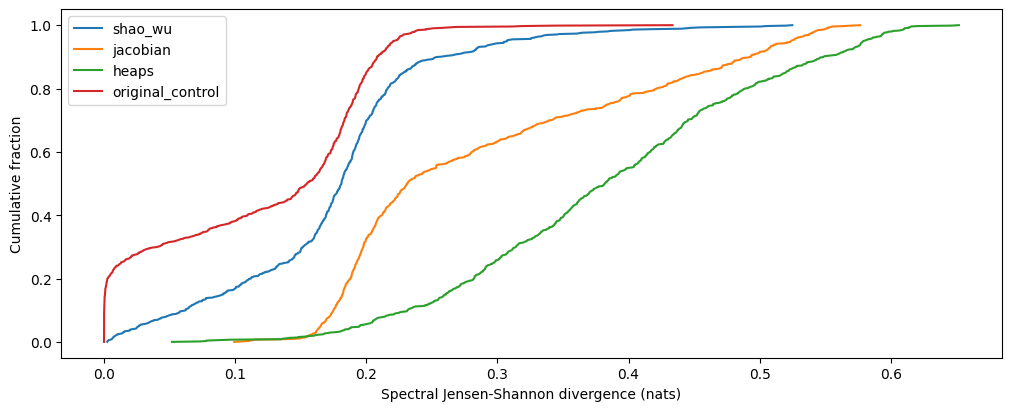

In [1]:
from pathlib import Path
import sys,json,time,platform,hashlib
from dataclasses import asdict,replace
import numpy as np,pandas as pd,matplotlib.pyplot as plt
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').exists())
sys.path.insert(0,str(root/'src'))
from tsfmxai.generators.multiseries import *
from tsfmxai.generators.combinatorial_expression import CombinatorialTreeConfig
from tsfmxai.generators.initialization import RandomHistorySpec,sample_random_history
from tsfmxai.generators.stochastic import simulate_innovation_path
from tsfmxai.evaluation.process_coverage import distribution_metrics
cfg=MultiseriesConfig(ast_config=CombinatorialTreeConfig(maximum_operators=4,maximum_lag=16,max_degree=4),channel_count_probs={1:1.},dependency_probs={'independent':1.},treatment_probs={'original':1.})
def z(x):return (x-x.mean())/(x.std()+1e-12)
def acf(x):return np.array([np.mean(z(x)[:-k]*z(x)[k:]) for k in (1,2,4,8,16)])
rows=[];counts=[];examples=[];start=time.perf_counter()
for retention in (True,):
 accepted_count=0;attempts=0;lagless=0;supports=set()
 for i in range(1000):
    s=sample_multiseries_system(replace(cfg,lag_sampling=cfg.lag_sampling if retention else None),seed=stream_seed(314159,i))
    noise=np.random.default_rng(stream_seed(314159,i,90)).uniform(-np.sqrt(3)*.05,np.sqrt(3)*.05,(1,256))
    for attempt in range(4):
        attempts+=1
        h,_=sample_random_history(RandomHistorySpec(),1,s.history_length,np.random.default_rng(stream_seed(314159,i,91,attempt)))
        x=simulate_innovation_path(s.expressions,s.bindings,h,noise)
        accepted=x.shape[1]==256 and np.isfinite(x).all() and np.max(np.abs(x))<np.finfo(np.float32).max
        if accepted:break
    if not accepted:continue
    accepted_count+=1
    lagless += int(s.history_length == 0)
    supports.add(s.canonical[0].skeleton)
    for method in ('shao_wu','jacobian','heaps'):
        if method=='jacobian' and not s.history_length:continue
        t=build_multiseries_system(equations=s.original_equations,allowed_sources={0:[0]},treatments=[TreatmentSpec(method)],innovations=[InnovationSpec('uniform' if method=='jacobian' else 'gaussian',.05)],max_degree=4)
        # Heaps may introduce memory for constant originals.
        history=h if h.shape[1]>=t.history_length else np.zeros((1,t.history_length))
        y=simulate_innovation_path(t.expressions,t.bindings,history,noise)
        assert y.shape==x.shape and np.isfinite(y).all()
        a,b=z(x[0]),z(y[0])
        row=dict(has_lags=bool(s.history_length),terminal_sampling=retention,index=i,method=method,correlation=float(np.mean(a*b)),rmse=float(np.sqrt(np.mean((a-b)**2))),acf_mae=float(np.mean(np.abs(acf(x[0])-acf(y[0])))),std_ratio=float(y.std()/(x.std()+1e-12)),original_acf=acf(x[0]).tolist(),treated_acf=acf(y[0]).tolist())
        # Compare normalized spectra and marginal distributions using library metrics.
        independent_noise=np.random.default_rng(stream_seed(314159,i,92)).uniform(-np.sqrt(3)*.05,np.sqrt(3)*.05,(1,256))
        for coupling, innovation in [('shared',noise),('independent',independent_noise)]:
            candidate = y if coupling == 'shared' else simulate_innovation_path(t.expressions,t.bindings,history,innovation)
            metrics=distribution_metrics(z(x[0])[None,:],z(candidate[0])[None,:],0)
            rows.append(dict(row,noise_coupling=coupling,**metrics))
        if method == 'shao_wu':
            control=simulate_innovation_path(s.expressions,s.bindings,h,independent_noise)
            valid_control=control.shape==x.shape and np.isfinite(control).all() and np.max(np.abs(control))<np.finfo(np.float32).max
            if valid_control:
                metrics=distribution_metrics(z(x[0])[None,:],z(control[0])[None,:],0)
                rows.append(dict(row,method='original_control',noise_coupling='independent',**metrics))
        if retention and method=='shao_wu':examples.append((row['rmse'],a,b))
 counts.append(dict(terminal_sampling=retention,candidates=1000,accepted=accepted_count,history_attempts=attempts,accepted_lagless=lagless,accepted_skeletons=len(supports)))
df=pd.DataFrame(rows)
lagged=df[df.has_lags]
summary=lagged.groupby(['method','noise_coupling'])[['psd_jsd','standardized_wasserstein']].median()
display(summary)
print(counts)
quantiles=lagged.groupby(['method','noise_coupling']).psd_jsd.quantile([.1,.5,.9])
display(quantiles)
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
for method in ['shao_wu','jacobian','heaps','original_control']:
    values=np.sort(lagged[(lagged.method==method)&(lagged.noise_coupling=='independent')].psd_jsd)
    ax.plot(values,np.arange(1,len(values)+1)/len(values),label=method)
ax.set(xlabel='Spectral Jensen-Shannon divergence (nats)',ylabel='Cumulative fraction');ax.legend();plt.show()


In [2]:
# COMPLETE EXPERIMENT RECORD
record=dict(question='Do normalized spectra and marginal distributions confirm paired similarity?',hypothesis='Shao-Wu remains closer under spectral metrics and independent innovations.',configuration=asdict(cfg),candidates=1000,seed=314159,streams='system(root,i); original noise(root,i,90); history(root,i,91,attempt); independent noise(root,i,92)',steps=256,max_history_attempts=4,initialization=asdict(RandomHistorySpec()),normalization='per trajectory mean zero unit std',noise='uniform +/-sqrt(3)*.05, controlled across methods',counts=counts,metrics=rows,summary=summary.reset_index().to_dict('records'),elapsed=time.perf_counter()-start,provenance=dict(python=sys.version,platform=platform.platform(),source_sha256={str(p.relative_to(root)):hashlib.sha256(p.read_bytes()).hexdigest() for p in (root/'src/tsfmxai').rglob('*.py')}),limitations=['Univariate 256-step finite-horizon acceptance','Independent same-original control is conditional on a finite second trajectory','Uniform control differs from default Gaussian innovations for Shao-Wu and Heaps','Heaps constructs a different mechanism','Single root seed'],scientific_summary='Interpret independent-noise comparisons against the original-control spectral divergence floor. Lower distances indicate closer spectra and marginal distributions.',reproduction='python -m jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=-1 experiments/multivariate_generation/06_spectral_confirmation/01_metrics.ipynb')
print(json.dumps(record))


{"question": "Do normalized spectra and marginal distributions confirm paired similarity?", "hypothesis": "Shao-Wu remains closer under spectral metrics and independent innovations.", "configuration": {"ast_config": {"minimum_operators": 1, "maximum_operators": 4, "num_series": 1, "minimum_lag": 1, "maximum_lag": 16, "max_degree": 4, "require_lag": true, "minimum_parameter_magnitude": 0.05, "maximum_parameter_magnitude": 0.9}, "channel_count_probs": {"1": 1.0}, "dependency_probs": {"independent": 1.0}, "treatment_probs": {"original": 1.0}, "max_external_sources": 2, "self_source_weight": 3.0, "allow_no_lags": true, "noise": {"std_range": [0.01, 0.1], "std_sampling": "uniform", "family_policy": "by_treatment"}, "target_gain": 0.8, "safety_factor": 0.95, "lag_sampling": {"minimum": 0.25, "maximum": 0.75, "tau": 1.0}}, "candidates": 1000, "seed": 314159, "streams": "system(root,i); original noise(root,i,90); history(root,i,91,attempt); independent noise(root,i,92)", "steps": 256, "max_his